# Exoplanet Demographics

This notebook queries a bounded sample of default NASA Exoplanet Archive solutions and uses Pergamon's demographic plotting pipeline. It compares measured mass and radius, places escape speed and incident flux beside the Earth-normalized scaling discussed by Zahnle and Catling (2017), and shows raw detected period-radius counts. The counts are not corrected for survey completeness and are not occurrence rates.

In [3]:
from pathlib import Path
import sys
import warnings

from IPython.display import Image, display

warnings.filterwarnings(
    "ignore",
    message="Unable to find acceptable character detection dependency.*",
)

search_roots = (Path.cwd(), *Path.cwd().parents)
repository_root = next(
    candidate for candidate in search_roots
    if candidate.name == "pergamon" and (candidate / "pyproject.toml").is_file()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

from pergamon.exoplanet_catalog import load_confirmed_exoplanets
from pergamon.exoplanet_demographics import add_demographic_quantities

catalog_limit = 25
planets = load_confirmed_exoplanets(limit=catalog_limit)
enriched_planets = add_demographic_quantities(planets)
measured_bulk_properties = enriched_planets["bulk_density_g_cm3"].notna().sum()
print(f"Retrieved {len(planets)} default archive solutions; {measured_bulk_properties} have measured mass and radius.")
print(f"Archive snapshot date: {planets['archive_retrieved_at_utc'].iloc[0][:10]} UTC.")

Retrieved 25 default archive solutions; 22 have measured mass and radius.
Archive snapshot date: 2026-10-23 UTC.


## Generate the Figures

Pergamon excludes archive-reported mass and radius limits from density and escape-speed calculations. The cosmic-shoreline guide is a reference scaling, not a fitted atmospheric-retention boundary.

exoplanet_mass_radius_density: exoplanet_mass_radius_density.png


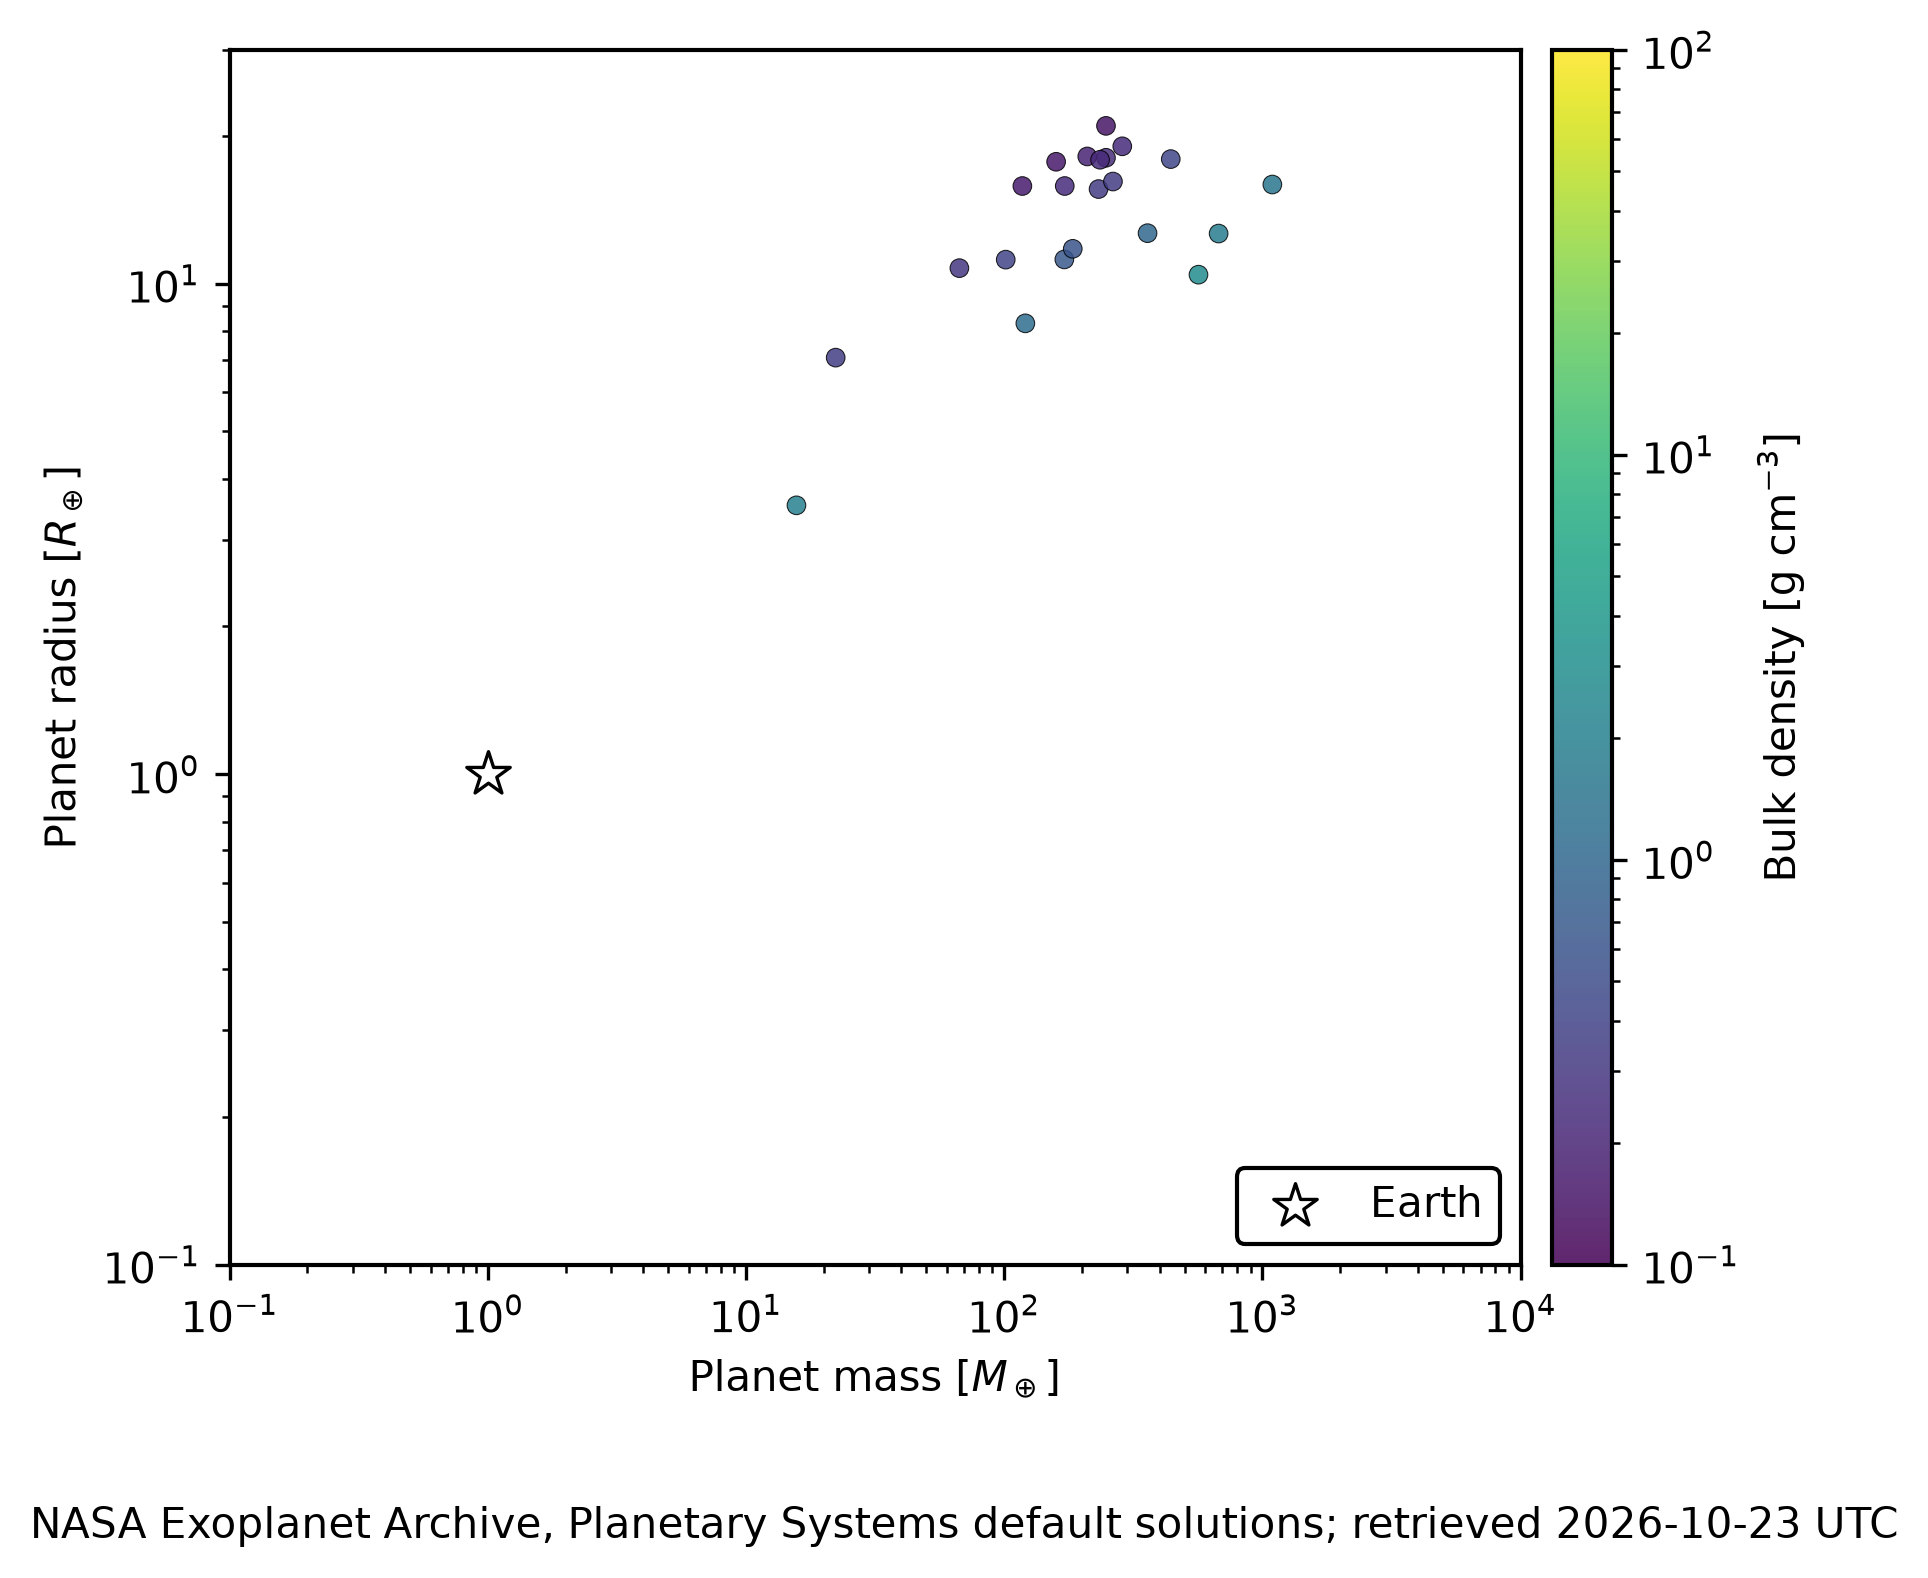

exoplanet_cosmic_shoreline: exoplanet_cosmic_shoreline.png


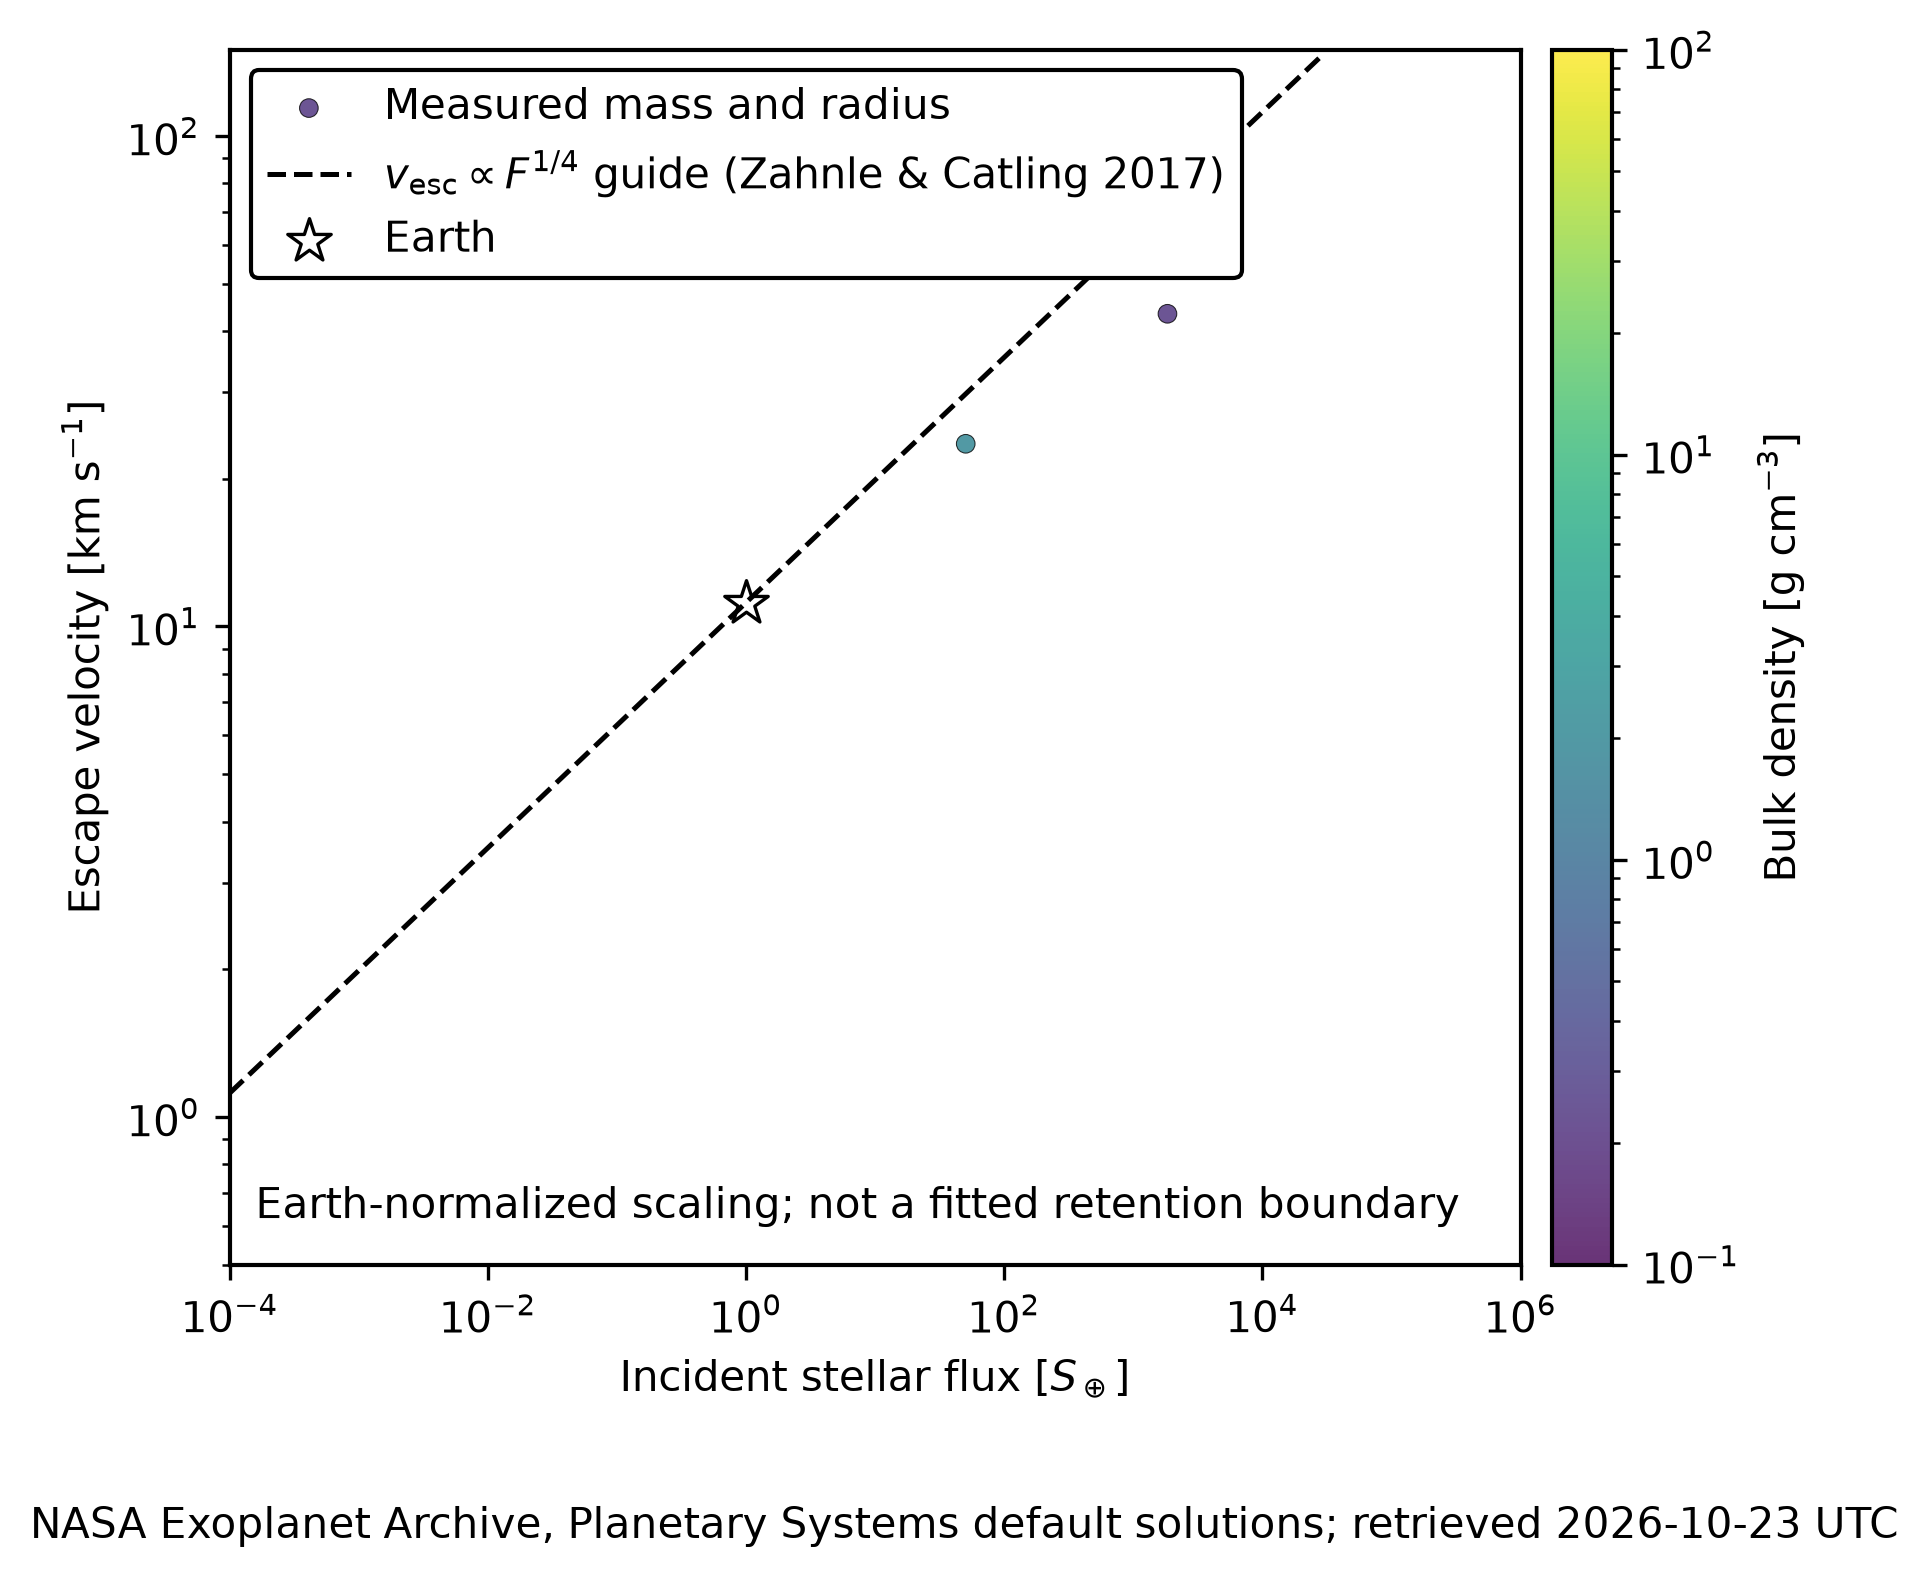

exoplanet_period_radius: exoplanet_period_radius.png


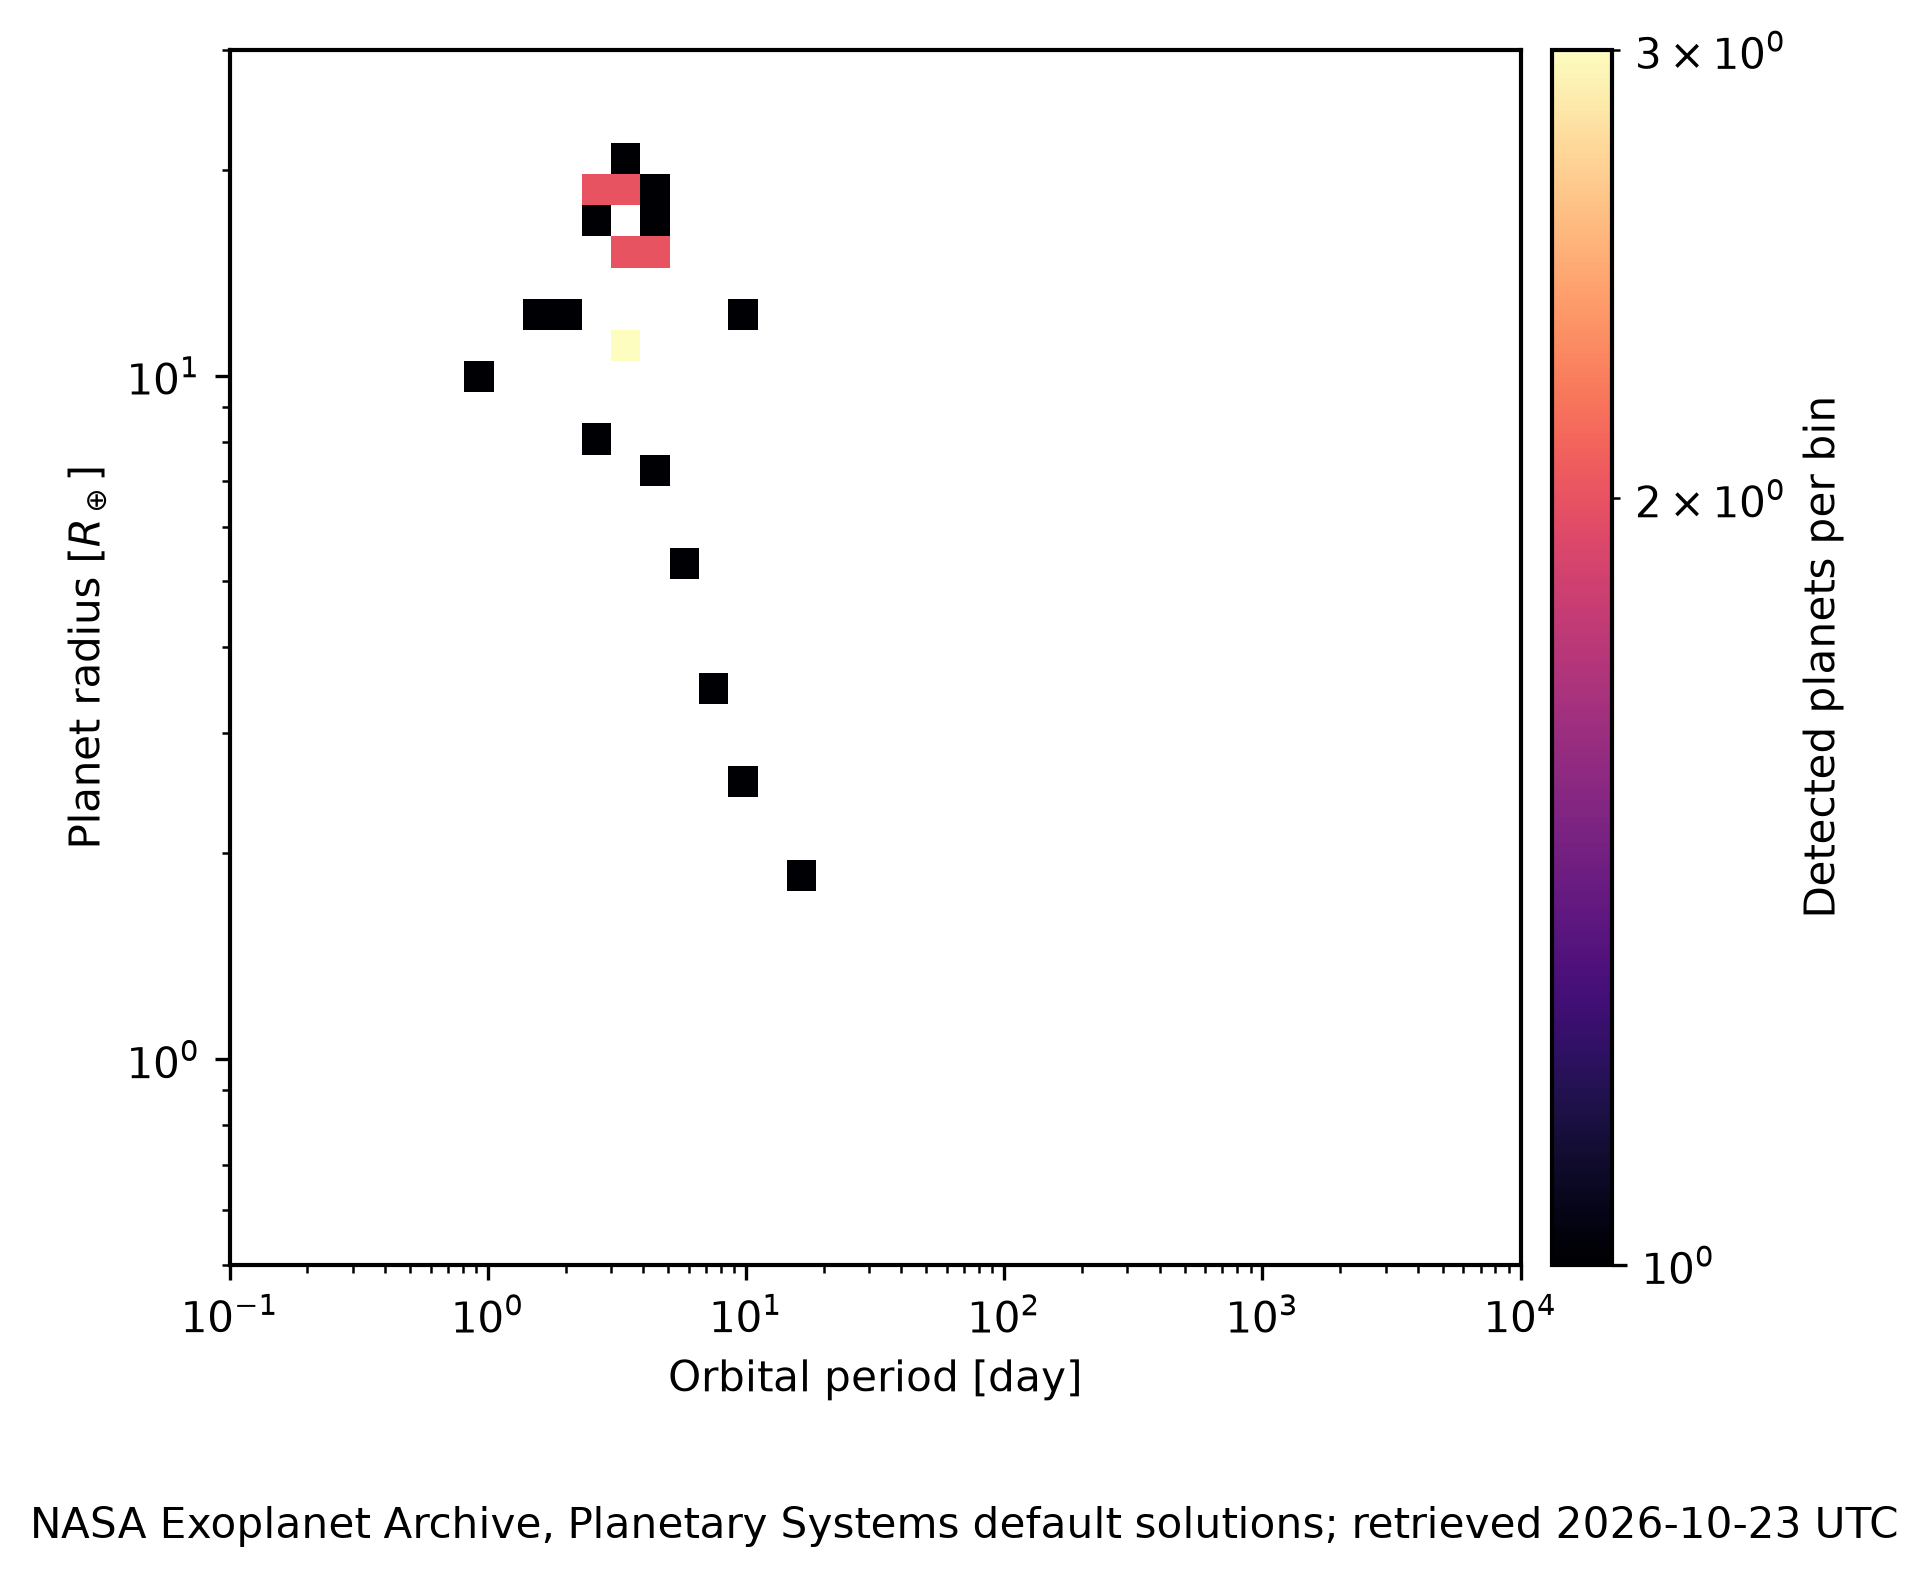

In [4]:
import os

from pergamon.exoplanet_demographics import plot_exoplanet_demographics

visuals_directory = Path(os.path.relpath(repository_root / "examples" / "visuals", Path.cwd()))
figure_paths = plot_exoplanet_demographics(planets, visuals_directory, typefileplot="png")
for figure_name, figure_path in figure_paths.items():
    print(f"{figure_name}: {figure_path.name}")
    display(Image(filename=str(figure_path)))